- Backbone  : ViT-Small/16 (≈22 M params, ImageNet pretrained)  
- Clients   : 5 clinets (Dirichlet-α = 0.15 skewed)  
- Dataset : MNIST (~60 k images)
- Epochs    : 3 per client  |  Batch size: 64  |  Checkpoints every epoch  

### 0. Google-Drive mount (skip on local Jupyter)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# ROOT_PATH = "/content/drive/MyDrive/Graduation Thesis/fl_localize_stitch_vit/"
ROOT_PATH = "/content/drive/Othercomputers/Victus/Disk D/New Uzb Semester 8/Graduation Thesis/fl_localize_stitch_vit/"
# ROOT_PATH = "./"              # to run locally

Mounted at /content/drive


#### 0a. Dependencies

In [ ]:
import subprocess, sys, importlib, pathlib, os

PKGS = ["torch", "torchvision", "timm", "tqdm"]
for pkg in PKGS:
    try:
        importlib.import_module(pkg)
    except ModuleNotFoundError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg])

In [ ]:
ROOT_PATH = pathlib.Path(ROOT_PATH).resolve()
sys.path.extend([str(ROOT_PATH)])

ckpt_dir = ROOT_PATH / "checkpoints"
ckpt_dir.mkdir(exist_ok=True)

### 1. Hyper-parameters & torchvision transforms  

In [ ]:
NUM_CLIENTS = 5
EPOCHS      = 4
BATCH_SIZE  = 64
IMG_SIZE    = 224   # ViT default patch‑16 grid
ALPHA       = 0.15   # Dirichlet concentration → stronger skew < 1, weaker skew > 1
SUBSET_FRAC = 0.1   # 10 % of MNIST

from torchvision import transforms
preprocess = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.expand(3, -1, -1)),
    transforms.Normalize((0.1307,)*3, (0.3081,)*3),
])

### 2. Data loading (with sub-sampling) & skewed client splits

In [ ]:
from torchvision.datasets import MNIST
from torch.utils.data import DataLoader, Subset
import torch, numpy as np, math

def downsample(ds, frac, seed=42):
    torch.manual_seed(seed)
    if frac >= 1.0:
        return ds
    n = math.ceil(len(ds) * frac)
    keep = torch.randperm(len(ds))[:n]
    return Subset(ds, keep)

DATA_ROOT = "./data"
train_ds_full = MNIST(DATA_ROOT, train=True,  download=True, transform=preprocess)
train_ds = downsample(train_ds_full, SUBSET_FRAC)

test_ds  = MNIST(DATA_ROOT, train=False, download=True, transform=preprocess)

# Dirichlet split

def create_skewed_clients(dataset, num_clients=NUM_CLIENTS, alpha=ALPHA, seed=42):
    rng = np.random.default_rng(seed)

    labels = np.array((dataset if isinstance(dataset, MNIST) else dataset.dataset).targets)[
        dataset.indices if isinstance(dataset, Subset) else slice(None)]

    class_indices = [np.where(labels == c)[0] for c in range(10)]
    clients = [[] for _ in range(num_clients)]
    for class_i in class_indices:
        rng.shuffle(class_i)
        parts = rng.dirichlet(alpha * np.ones(num_clients))
        splits = (np.cumsum(parts) * len(class_i)).astype(int)[:-1]
        for cli, chunk in zip(clients, np.split(class_i, splits)):
            cli.extend(chunk)
    return clients

client_class_i = create_skewed_clients(train_ds)
get_loader = lambda idxs: DataLoader(Subset(train_ds, idxs), batch_size=BATCH_SIZE,
                                     shuffle=True, num_workers=2, pin_memory=True)
train_loaders = [get_loader(idx) for idx in client_class_i]

test_loader = DataLoader(test_ds, batch_size=256, shuffle=False,
                         num_workers=2, pin_memory=True)

100%|██████████| 9.91M/9.91M [00:00<00:00, 56.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.78MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.43MB/s]


### 3. ViT-Small/16 model

In [ ]:
import timm, torch.nn as nn

BACKBONE_NAME = "vit_small_patch16_224"  # ~22 M parameters

def make_classifier(num_classes: int = 10):     # MNIST 10 classes
    model = timm.create_model(BACKBONE_NAME, pretrained=True)
    return model

### 4. Train Clients

In [ ]:
from torch.optim import AdamW
from torch.nn.functional import cross_entropy
from tqdm import tqdm

def train_model(model, loader, client_id, epochs=EPOCHS, device="cuda"):
    model.to(device)

    opt = AdamW(model.parameters(), lr=3e-4)
    scaler = torch.amp.GradScaler('cuda')

    for ep in range(1, epochs+1):
        model.train()

        pbar = tqdm(loader, desc=f"Client{client_id} Epoch{ep}")
        for x, y in pbar:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad()

            with torch.amp.autocast('cuda'):
                out = model(x)
                loss = cross_entropy(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()

        # Checkpoint
        torch.save(model.state_dict(), ckpt_dir / f"client{client_id}_ep{ep}.pt")

    return model.cpu().eval()          # leave in eval mode!

In [ ]:
# Train all clients
client_models = []
for cid, ld in enumerate(train_loaders):
    client_models.append(train_model(make_classifier(), ld, cid))

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Client4 Epoch4: 100%|██████████| 13/13 [00:02<00:00,  5.04it/s]


#### Or load weights (state dict) from a checkpoint:

In [ ]:
client_models = []
ckpt_dir = pathlib.Path(ROOT_PATH) / "checkpoints"

for cid in range(NUM_CLIENTS):
    model = timm.create_model(BACKBONE_NAME)

    client_ckpt = f"client{cid}_ep{EPOCHS}.pt"
    state = torch.load(ckpt_dir / client_ckpt, map_location="cpu")

    model.load_state_dict(state, strict=True)
    client_models.append(model.eval())

#### 4a. Evaluate clients separately

Let's see what are the **client accuracies** trained on **imbalanced data**:

In [ ]:
def accuracy(model):
    model.eval().cuda()
    preds, labels = [], []

    with torch.no_grad():
        for x, y in test_loader:
            preds.extend(model(x.cuda()).argmax(1).cpu().numpy())
            labels.extend(y.numpy())
    model.cpu()
    return (np.array(preds) == np.array(labels)).mean()

In [ ]:
import copy

print("Client local accuracies:")

for cid, (clmodel, ld) in enumerate(zip(client_models, train_loaders)):
    acc   = accuracy(clmodel)
    print(f"  client{cid}:  {acc:.4f}")

Client local accuracies:
  client0:  0.6843
  client1:  0.4058
  client2:  0.2411
  client3:  0.0958
  client4:  0.0892


### 5. Localizer

In [ ]:
import torch
from typing import Dict, List

class SimpleLocalizer:
    def __init__(self, pretrained: nn.Module, finetuned: nn.Module, K=0.95):
        # δ = θ_finetuned − θ_pretrained
        self.delta = {n: (f.detach() - p.detach())     # task vector
                      for (n, p), (_, f) in zip(pretrained.named_parameters(),
                                                finetuned.named_parameters())}

        # global threshold for top-k magnitude
        all_vals = torch.cat([d.flatten().abs() for d in self.delta.values()])
        k = max(1, int(K * all_vals.numel()))    # max() is for safety: to choose at least one
        thresh = torch.topk(all_vals, k).values[-1]     # topk() returns [(values), (indices)] in decreasing order.

        # sparse task vector τ = m ⊙ δ
        self.task_vec = {n: (d * (d.abs() >= thresh)).clone() for n, d in self.delta.items()}

    def task_vector(self):
        return self.task_vec

In [ ]:
task_vectors = []
pretrained = timm.create_model(BACKBONE_NAME, pretrained=False).eval()

for cid, clmodel in enumerate(client_models):
    print(f"Localizing client {cid}")
    task_vectors.append(SimpleLocalizer(pretrained, clmodel, K=0.50).task_vector())

Localizing client 0
Localizing client 1
Localizing client 2
Localizing client 3
Localizing client 4


### 6. Stitch task vectors
top-k% largest magnitude weights, Yadav et al. 2023

In [ ]:
import copy
def simpleStitcher(pretrained: nn.Module, task_vectors: List[Dict[str, torch.Tensor]]):
    merged = pretrained.state_dict()

    # given a weight w, merged[n][w] = sum(tv[n][w] for tv in task_vectors) / (the number of clients whose weight w is not zero)
    for n in merged:
        numer = sum(tv[n] for tv in task_vectors)
        denom = torch.zeros_like(numer)
        # denom += NUM_CLIENTS

        # a = task_vectors[0][n] != 0
        # denom += a
        # print(denom);break

        for tv in task_vectors:
            denom += (tv[n] != 0)
        denom.clamp_min_(1)
        merged[n] += numer / denom

    new_model = copy.deepcopy(pretrained)
    new_model.load_state_dict(merged, strict=True)

    return new_model.eval()

In [ ]:
stitched_model = simpleStitcher(pretrained, task_vectors)

#### 6a. To simulate Multi-Round Communication merging with the LaS algorithm, FedAvg, Gaussian DP-FedAvg

[RUN THE `8. Evaluation` cells FIRST]

In [ ]:
N = 11
fedavg_accuracy = [fedavg_acc]
stitched_accuracy = [stitched_acc]
fedavgnoise_accuracy = [fedavgnoise_acc]

for i in range(N):
    # Load new train data
    client_class_i = create_skewed_clients(downsample(train_ds_full, SUBSET_FRAC, seed=i+42))
    get_loader = lambda idxs: DataLoader(Subset(train_ds, idxs), batch_size=BATCH_SIZE,
                                        shuffle=True, num_workers=2, pin_memory=True)
    train_loaders = [get_loader(idx) for idx in client_class_i]

    # Train
    client_models_las = []
    for cid, ld in enumerate(train_loaders):
        client_models_las.append(train_model(copy.deepcopy(stitched_model), ld, cid, epochs=1))

    client_models_fedavg = []
    for cid, ld in enumerate(train_loaders):
        client_models_fedavg.append(train_model(copy.deepcopy(fedavg_model), ld, cid, epochs=1))

    client_models_fedavgnoise = []
    for cid, ld in enumerate(train_loaders):
        client_models_fedavgnoise.append(train_model(copy.deepcopy(fedavgnoise_model), ld, cid, epochs=1))


    # a. FedAvg
    fedavg_model  = weight_average(client_models_fedavg).eval()

    # b. LaS algorithm
    task_vectors = []
    # Localize
    for cid, clmodel in enumerate(client_models_las):
        task_vectors.append(SimpleLocalizer(stitched_model, clmodel, K=0.50).task_vector())    # K = 1 - µ*prev_acc
    # Stitch
    stitched_model = simpleStitcher(stitched_model, task_vectors)

    # c. FedAvg Noise
    fedavgnoise_model = weight_average_noise(client_models_fedavgnoise).eval()


    # Evaluate
    fedavg_acc = accuracy(fedavg_model)
    stitched_acc = accuracy(stitched_model)
    fedavgnoise_acc = accuracy(fedavgnoise_model)

    fedavg_accuracy.append(fedavg_acc)
    stitched_accuracy.append(stitched_acc)
    fedavgnoise_accuracy.append(fedavgnoise_acc)

    print(f"Round {i+2}: FedAvg acc={fedavg_acc}, LaS acc={stitched_acc}, FedAvgNoise acc={fedavgnoise_acc}")

Client4 Epoch1: 100%|██████████| 13/13 [00:03<00:00,  4.04it/s]


Round 2: FedAvg acc=0.1135, LaS acc=0.0958, FedAvgNoise acc=0.1941


Client4 Epoch1: 100%|██████████| 22/22 [00:04<00:00,  4.64it/s]


Round 3: FedAvg acc=0.5854, LaS acc=0.655, FedAvgNoise acc=0.8153


Client4 Epoch1: 100%|██████████| 21/21 [00:04<00:00,  4.36it/s]


Round 4: FedAvg acc=0.7485, LaS acc=0.5314, FedAvgNoise acc=0.9495


... (12 outputs left out)

Client4 Epoch1: 100%|██████████| 24/24 [00:05<00:00,  4.26it/s]


Round 11: FedAvg acc=0.9893, LaS acc=0.9764, FedAvgNoise acc=0.9883


Client4 Epoch1: 100%|██████████| 20/20 [00:04<00:00,  4.48it/s]


Round 12: FedAvg acc=0.9901, LaS acc=0.9774, FedAvgNoise acc=0.9894


### 7.  Baselines

#### Single fine-tuned model

A single model trained on the union of all client data.

In [ ]:
union_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True)    # data loader on the whole dataset (which is the union of all clients datasets)

baseline_model = train_model(make_classifier(), union_loader, "Baseline", epochs=4)

ClientBaseline Epoch4: 100%|██████████| 94/94 [00:18<00:00,  5.13it/s]


Or load from a checkpoint:

In [ ]:
ckpt_dir = pathlib.Path(ROOT_PATH) / "checkpoints"

baseline_model = timm.create_model(BACKBONE_NAME)
baseline_ckpt = f"clientBaseline_ep2.pt"

state = torch.load(ckpt_dir / baseline_ckpt, map_location="cpu")
baseline_model.load_state_dict(state, strict=True)


VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False)
        (norm): Identity(

#### FedAvg (weight average)

In [ ]:
def weight_average(models):
    avg = copy.deepcopy(models[0])
    with torch.no_grad():
        for k in avg.state_dict().keys():
            avg.state_dict()[k].copy_(
                sum(m.state_dict()[k] for m in models) / len(models))
    return avg

fedavg_model  = weight_average(client_models).eval()

In [ ]:
def weight_average_noise(models):
    avg = copy.deepcopy(models[0])
    with torch.no_grad():
        for k in avg.state_dict().keys():
            avg.state_dict()[k].copy_(
                sum(m.state_dict()[k] for m in models) / len(models)
            )
            # add normal noise
            avg.state_dict()[k] += torch.normal(mean=0, std=torch.std(avg.state_dict()[k]) * 0.05, size=avg.state_dict()[k].shape)

    return avg

fedavgnoise_model  = weight_average_noise(client_models).eval()

### 8. Evaluation

In [ ]:
fedavg_acc = accuracy(fedavg_model)
fedavg_acc

np.float64(0.1119)

In [ ]:
fedavgnoise_acc = accuracy(fedavgnoise_model)
fedavgnoise_acc

np.float64(0.1693)

In [ ]:
stitched_acc = accuracy(stitched_model)
stitched_acc

np.float64(0.0892)

In [ ]:
baseline_acc = accuracy(baseline_model)
baseline_acc

np.float64(0.9828)

Paper's Dataless LaS (not modified) –         # acc=0.9867 in 15 iterations.  
FedAvg –                       # acc=0.9887 in 5 iterations.

### Plot

initial K=0.95

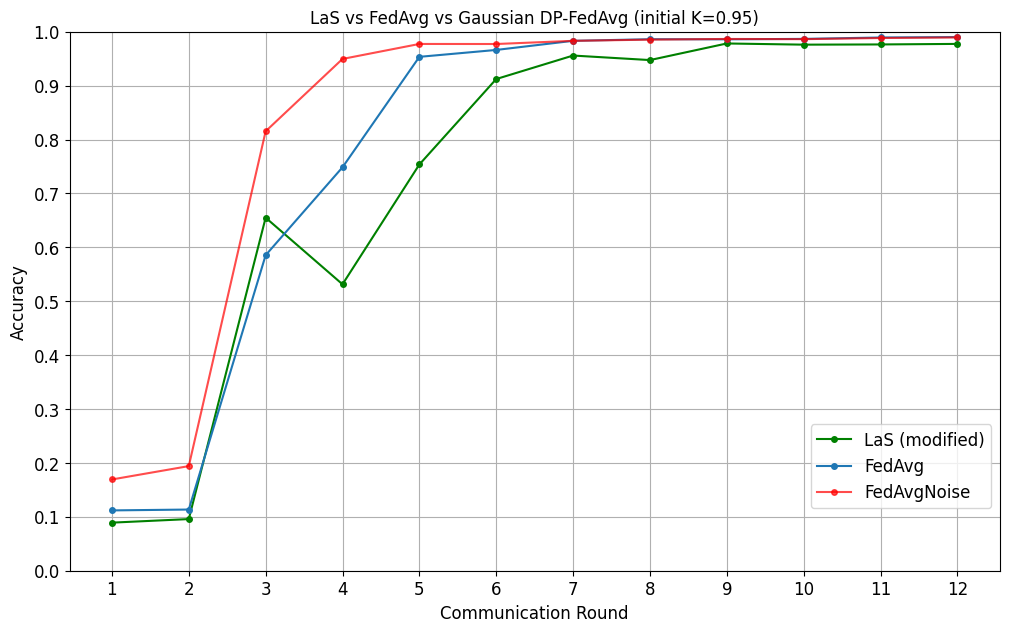

In [ ]:
import matplotlib.pyplot as plt

x_values = range(1, N+2)

plt.figure(figsize=(12, 7))
plt.plot(x_values, stitched_accuracy, label='LaS (modified)', color='green', marker='o', markersize=4)
plt.plot(x_values, fedavg_accuracy, label='FedAvg', marker='o', markersize=4)
plt.plot(x_values, fedavgnoise_accuracy, label='FedAvgNoise', color='red', alpha=0.7, marker='o', markersize=4)


plt.xlabel('Communication Round', fontsize='large')
plt.ylabel('Accuracy', fontsize='large')
plt.title('LaS vs FedAvg vs Gaussian DP-FedAvg (initial K=0.95)')

# Set x-axis ticks to integers
plt.xticks(x_values)

# Set y-axis ticks with increments of 0.1
plt.yticks([i / 10 for i in range(11)])
plt.tick_params(axis='both', labelsize='large')  # Increase tick font size

plt.ylim(0, 1)  # Set Y-axis limits from 0 to 1

# Move legend lower
plt.legend(loc='lower right', bbox_to_anchor=(1, 0.1), fontsize='large')
plt.grid(True)

# Save the plot as a vector image
plt.savefig('comparison_95.svg', format='svg')  # Use .svg, .pdf, or .eps for vector formats

plt.show()